Processing: 261124_TGA_P2.csv
Processing: 261124_TGA_phDADQ@P2.csv


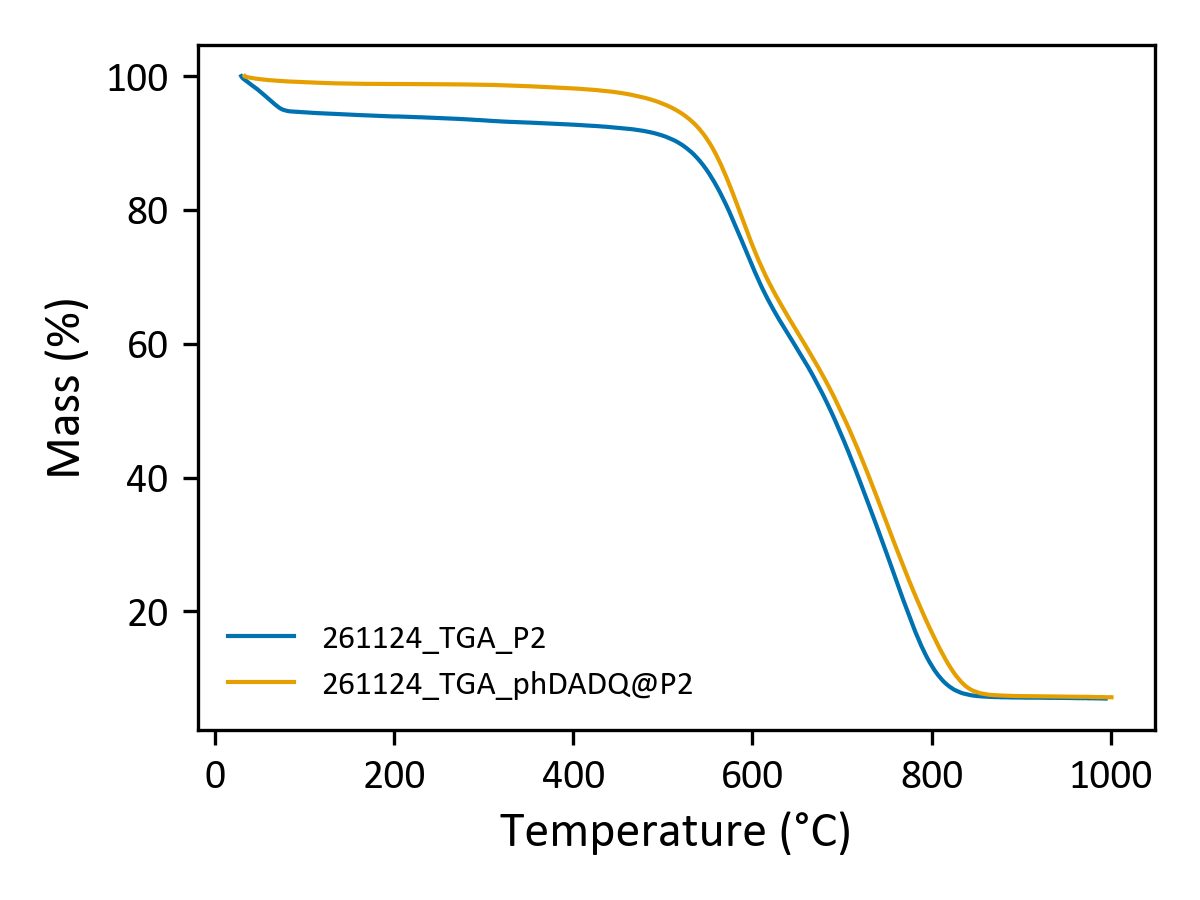

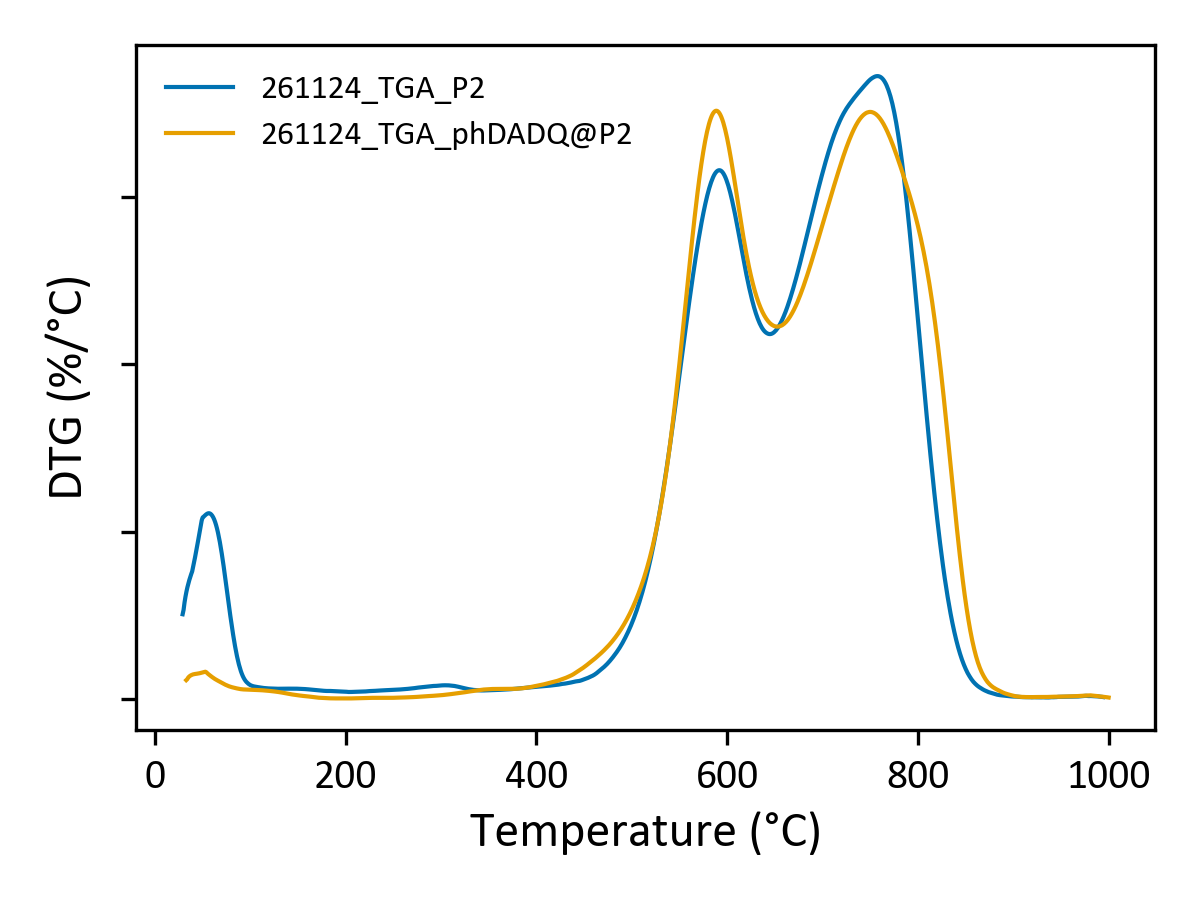

✅ All files processed successfully!


In [13]:
# =====================================================================
# TGA & DTG Automated Folder Processing (Ts;percentage format)
# =====================================================================
%matplotlib widget
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1. DIRECTORY & RANGE CONFIGURATION
# =========================
target_dir = Path(r"H:\FUBerlin\Measurements\TGA\SalomeF")

T_MIN = 0   # °C (usa None si no quieres límite inferior)
T_MAX = 2000   # °C (usa None si no quieres límite superior)


# =========================
# 2. FILE PARSING, TRIMMING & DTG
# =========================
def load_tga(file_path):
    """Lee archivos delimitados por ';' (Ts;percentage) y conserva solo el calentamiento."""
    df = pd.read_csv(file_path, sep=";", encoding="latin1")
    df.columns = df.columns.str.strip()
    df = df.rename(columns={"Ts": "Temperature", "percentage": "Mass (%)"})

    df["Temperature"] = pd.to_numeric(df["Temperature"], errors="coerce")
    df["Mass (%)"] = pd.to_numeric(df["Mass (%)"], errors="coerce")
    df = df.dropna(subset=["Temperature", "Mass (%)"])

    # Conservar solo la rampa de calentamiento
    max_idx = df["Temperature"].idxmax()
    df = df.loc[:max_idx].copy()

    # Opcional: descomenta las siguientes 2 líneas si quieres forzar el inicio a 100%
    # m0 = df["Mass (%)"].head(10).mean()
    # df["Mass (%)"] = df["Mass (%)"] / m0 * 100

    df["Label"] = file_path.stem
    return df[["Temperature", "Mass (%)", "Label"]]


def trim_tga(df, t_min=None, t_max=None):
    """Recorta el DataFrame de TGA al rango de temperatura [t_min, t_max]."""
    mask = pd.Series(True, index=df.index)
    if t_min is not None:
        mask &= df["Temperature"] >= t_min
    if t_max is not None:
        mask &= df["Temperature"] <= t_max
    return df.loc[mask].copy()


def compute_dtg(df, step=1.0, window=20):
    """Calcula la DTG con el método original (interpolación + rolling + gradient + rolling)."""
    label = df["Label"].iloc[0]

    # sort and remove duplicates for interpolation
    df_dtg = df.sort_values("Temperature").drop_duplicates("Temperature")

    # uniform temperature grid
    temp_uniform = np.arange(
        df_dtg["Temperature"].min(),
        df_dtg["Temperature"].max(),
        step
    )

    mass_uniform = np.interp(
        temp_uniform,
        df_dtg["Temperature"],
        df_dtg["Mass (%)"]
    )

    # smoothing
    mass_smooth = (
        pd.Series(mass_uniform)
        .rolling(window, center=True, min_periods=1)
        .mean()
        .values
    )

    # derivative
    dtg = np.gradient(mass_smooth, temp_uniform)

    # TGA convention: mass loss positive
    dtg = -dtg

    # second smoothing
    dtg = (
        pd.Series(dtg)
        .rolling(window, center=True, min_periods=1)
        .mean()
        .values
    )

    return pd.DataFrame({
        "Temperature": temp_uniform,
        "DTG (%/°C)": dtg,
        "Label": label
    })


# =========================
# 3. STYLING CONFIGURATION
# =========================
poster_style = {
    "figsize": (4, 3),
    "dpi": 300,
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "font_family": "Calibri",
    "line_width": 1,
    "linestyles": ["-", "-", "-", "-", "-", "-"],
    "colors": [
        "#0072B2", "#E69F00", "#009E73",
        "#CC79A7", "#56B4E9", "#D55E00", "#F0E442"
    ],
    "grid": False,
    "title_weight": "normal",
    "label_weight": "normal",
    "legend_frame": False,
    "tick_size": 10,
}

def apply_plot_style(style):
    plt.rcParams.update({
        "font.size": style["font_size"],
        "font.family": style["font_family"],
        "axes.titlesize": style["title_size"],
        "axes.labelsize": style["label_size"],
        "legend.fontsize": style["legend_size"],
        "xtick.labelsize": style["tick_size"],
        "ytick.labelsize": style["tick_size"],
    })


# =========================
# 4. PLOTTING FUNCTIONS
# =========================
def plot_tga(data, style=poster_style):
    apply_plot_style(style)
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])

    colors = style["colors"]
    linestyles = style["linestyles"]

    for i, df in enumerate(data):
        label = df["Label"].iloc[0]
        ax.plot(
            df["Temperature"], df["Mass (%)"],
            label=label,
            linewidth=style["line_width"],
            color=colors[i % len(colors)] if colors else None,
            linestyle=linestyles[i % len(linestyles)] if linestyles else "-"
        )

    ax.set_xlabel("Temperature (°C)", fontsize=style["label_size"])
    ax.set_ylabel("Mass (%)", fontsize=style["label_size"])
    ax.set_xlim(None, None)
    ax.legend(fontsize=style["legend_size"], frameon=style["legend_frame"])

    if style["grid"]:
        ax.grid(alpha=0.3)

    plt.tight_layout()
    return fig


def plot_dtg(data, style=poster_style):
    apply_plot_style(style)
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])

    colors = style["colors"]
    linestyles = style["linestyles"]

    for i, df in enumerate(data):
        label = df["Label"].iloc[0]
        ax.plot(
            df["Temperature"], df["DTG (%/°C)"],
            label=label,
            linewidth=style["line_width"],
            color=colors[i % len(colors)] if colors else None,
            linestyle=linestyles[i % len(linestyles)] if linestyles else "-"
        )

    ax.set_xlabel("Temperature (°C)", fontsize=style["label_size"])
    ax.set_ylabel("DTG (%/°C)", fontsize=style["label_size"])
    ax.set_xlim(None, None)
    ax.legend(fontsize=style["legend_size"], frameon=style["legend_frame"])
    ax.set_yticklabels([])

    if style["grid"]:
        ax.grid(alpha=0.3)

    plt.tight_layout()
    return fig


# =========================
# 5. AUTOMATED LOADING & EXECUTION
# =========================
TGA_DFs = []
DTG_DFs = []

file_list = sorted(
    p for p in target_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".txt", ".csv"}
)

if not file_list:
    print(f"⚠️ Warning: No .txt or .csv files found in {target_dir}")
else:
    for file_path in file_list:
        print(f"Processing: {file_path.name}")
        try:
            # 1. Cargar -> 2. Recortar -> 3. Derivar
            df_raw = load_tga(file_path)
            tga_df = trim_tga(df_raw, t_min=T_MIN, t_max=T_MAX)
            dtg_df = compute_dtg(tga_df)

            TGA_DFs.append(tga_df)
            DTG_DFs.append(dtg_df)

        except Exception as e:
            print(f"❌ Error processing {file_path.name}: {e}")

if TGA_DFs:
    fig_tga = plot_tga(TGA_DFs)
    # fig_tga.savefig(target_dir / "TGA_Plot.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig_dtg = plot_dtg(DTG_DFs)
    # fig_dtg.savefig(target_dir / "DTG_Plot.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("✅ All files processed successfully!")